# Advanced Statistical Analysis & Hypothesis Testing
**Assignment notebook | Significance level:** α = 0.05

## Objective
Use the Iris dataset to demonstrate descriptive statistics, normality tests, independent two-sample tests, one-way ANOVA, two-way ANOVA, Tukey HSD, confidence intervals, plots, and written interpretations.

**Dataset:** Iris, 150 observations, three species, and four numeric flower measurements. It is bundled with scikit-learn, so no separate dataset download is needed. [Dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html).

**Important limitation:** Iris has only one natural categorical grouping variable (species). To demonstrate two-way ANOVA, this notebook creates a low/high petal-width factor using the median. This is a teaching demonstration, not a claim that the derived factor is an independent biological treatment. For a real research analysis, use a dataset with two naturally observed categorical factors and justify the model in advance.

### Decision rule
For each test, compare the p-value with 0.05. If p < 0.05, reject the null hypothesis; otherwise, fail to reject it. A p-value is not the probability that the null hypothesis is true.

## 1. Import libraries and load the dataset

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import t
from sklearn.datasets import load_iris
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.diagnostic import lilliefors

ALPHA = 0.05
sns.set_theme(style="whitegrid")

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns=["target"])
df = df.rename(columns={
    "sepal length (cm)": "sepal_length",
    "sepal width (cm)": "sepal_width",
    "petal length (cm)": "petal_length",
    "petal width (cm)": "petal_width"
})

print("Dataset shape:", df.shape)
display(df.head())
print("\nSpecies counts:")
display(df["species"].value_counts())
print("\nMissing values:")
display(df.isna().sum())

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Species counts:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Missing values:


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

## 2. Descriptive statistics and distribution plots

,n,sepal_length_mean,sepal_length_sd,petal_width_mean
species,,,,
setosa,50,5.006,0.352,0.246
versicolor,50,5.936,0.516,1.326
virginica,50,6.588,0.636,2.026


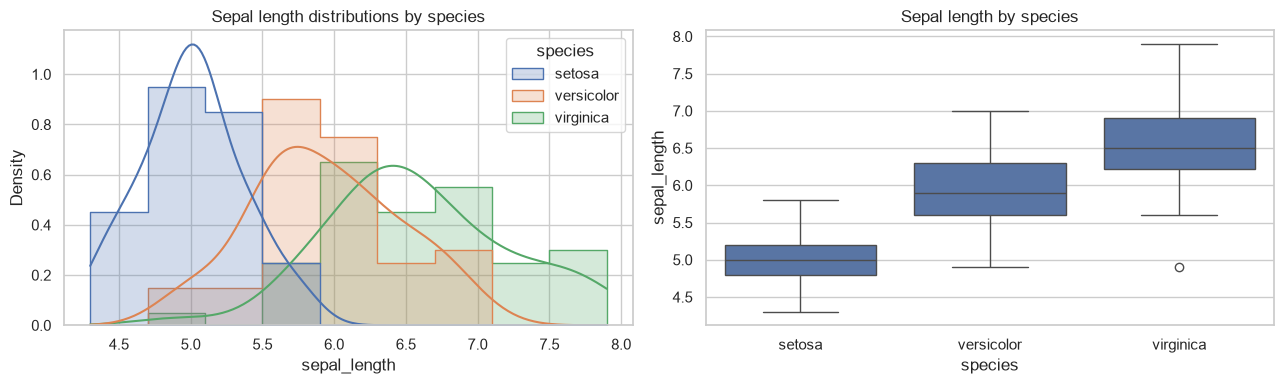

<Figure size 600x500 with 0 Axes>

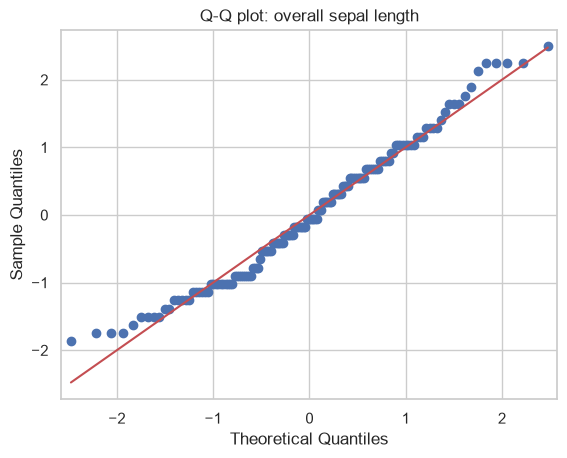

In [2]:
display(df.groupby("species").agg(
    n=("sepal_length", "size"),
    sepal_length_mean=("sepal_length", "mean"),
    sepal_length_sd=("sepal_length", "std"),
    petal_width_mean=("petal_width", "mean")
).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="sepal_length", hue="species", kde=True,
             element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Sepal length distributions by species")
sns.boxplot(data=df, x="species", y="sepal_length", ax=axes[1])
axes[1].set_title("Sepal length by species")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sm.qqplot(df["sepal_length"], line="s", fit=True)
plt.title("Q-Q plot: overall sepal length")
plt.show()

## 3. Normality tests: Shapiro–Wilk and Kolmogorov–Smirnov

For each species, test sepal length.

- **H₀:** The sample is consistent with a normal distribution.
- **H₁:** The sample is not consistent with a normal distribution.

The ordinary one-sample KS test assumes the reference distribution is fully specified in advance. Since we estimate the normal mean and standard deviation from the same sample, the notebook reports the **Lilliefors-corrected KS test** (a correction for estimated normal parameters) alongside Shapiro–Wilk. The code also includes the raw standardized KS statistic for transparency, but its p-value should not be treated as a properly calibrated normality test when parameters are estimated.

In [3]:
normality_rows = []
for species, group in df.groupby("species"):
    x = group["sepal_length"].dropna().to_numpy()
    sh_stat, sh_p = stats.shapiro(x)
    lf_stat, lf_p = lilliefors(x, dist="norm")
    z = (x - x.mean()) / x.std(ddof=1)
    raw_ks_stat, raw_ks_p = stats.kstest(z, "norm")
    normality_rows.append({
        "species": species,
        "Shapiro_W_stat": sh_stat,
        "Shapiro_W_p": sh_p,
        "Lilliefors_KS_stat": lf_stat,
        "Lilliefors_KS_p": lf_p,
        "Raw_standardized_KS_p_not_calibrated": raw_ks_p
    })

normality = pd.DataFrame(normality_rows)
display(normality.round(5))
print("Interpretation: for Shapiro–Wilk and Lilliefors, p < 0.05 suggests evidence against normality.")

,species,Shapiro_W_stat,Shapiro_W_p,Lilliefors_KS_stat,Lilliefors_KS_p,Raw_standardized_KS_p_not_calibrated
0,setosa,0.97770,0.45951,0.11486,0.09684,0.48892
1,versicolor,0.97784,0.46474,0.09624,0.29340,0.70712
2,virginica,0.97118,0.25831,0.11503,0.09583,0.48700


Interpretation: for Shapiro–Wilk and Lilliefors, p < 0.05 suggests evidence against normality.


## 4. Independent two-sample t-test and Mann–Whitney U test

Compare sepal length for **Iris setosa** and **Iris versicolor**.

### Hypotheses
- **T-test H₀:** The population mean sepal lengths are equal.
- **T-test H₁:** The population mean sepal lengths differ.
- **Mann–Whitney H₀:** The two groups have the same distribution (under a location-shift interpretation, this is often used to compare locations).
- **Mann–Whitney H₁:** The distributions differ.

Welch's t-test is used because it does not assume equal population variances. A 95% confidence interval is calculated for the difference in means (setosa − versicolor).

Setosa mean (SD): 5.006 (0.352), n=50
Versicolor mean (SD): 5.936 (0.516), n=50
Welch t-test: t=-10.5210, df=86.54, p=3.74674e-17
95% CI for mean difference (setosa - versicolor): [-1.106, -0.754] cm
Mann–Whitney U: U=168.50, p=8.34583e-14

T-test decision: Reject H0
Mann–Whitney decision: Reject H0


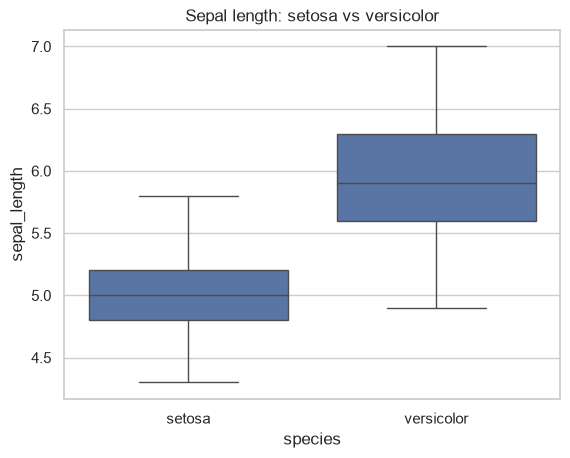

In [4]:
setosa = df.loc[df["species"] == "setosa", "sepal_length"].to_numpy()
versicolor = df.loc[df["species"] == "versicolor", "sepal_length"].to_numpy()

t_stat, t_p = stats.ttest_ind(setosa, versicolor, equal_var=False)
mw_stat, mw_p = stats.mannwhitneyu(setosa, versicolor, alternative="two-sided")

# Welch-Satterthwaite confidence interval for mean difference
mean_diff = setosa.mean() - versicolor.mean()
se_diff = np.sqrt(setosa.var(ddof=1)/len(setosa) +
                  versicolor.var(ddof=1)/len(versicolor))
df_welch = (setosa.var(ddof=1)/len(setosa) + versicolor.var(ddof=1)/len(versicolor))**2 / (
    (setosa.var(ddof=1)/len(setosa))**2/(len(setosa)-1) +
    (versicolor.var(ddof=1)/len(versicolor))**2/(len(versicolor)-1)
)
crit = stats.t.ppf(0.975, df_welch)
ci_low, ci_high = mean_diff - crit*se_diff, mean_diff + crit*se_diff

print(f"Setosa mean (SD): {setosa.mean():.3f} ({setosa.std(ddof=1):.3f}), n={len(setosa)}")
print(f"Versicolor mean (SD): {versicolor.mean():.3f} ({versicolor.std(ddof=1):.3f}), n={len(versicolor)}")
print(f"Welch t-test: t={t_stat:.4f}, df={df_welch:.2f}, p={t_p:.6g}")
print(f"95% CI for mean difference (setosa - versicolor): [{ci_low:.3f}, {ci_high:.3f}] cm")
print(f"Mann–Whitney U: U={mw_stat:.2f}, p={mw_p:.6g}")
print("\nT-test decision:", "Reject H0" if t_p < ALPHA else "Fail to reject H0")
print("Mann–Whitney decision:", "Reject H0" if mw_p < ALPHA else "Fail to reject H0")

sns.boxplot(data=df[df["species"].isin(["setosa", "versicolor"])],
            x="species", y="sepal_length")
plt.title("Sepal length: setosa vs versicolor")
plt.show()

## 5. One-way ANOVA and Tukey HSD post-hoc analysis

### Hypotheses
- **H₀:** Mean sepal length is equal across all three species.
- **H₁:** At least one species mean differs.

ANOVA tests the overall difference. Tukey HSD then identifies which pairs differ while adjusting for multiple comparisons.

,sum_sq,df,F,PR(>F)
C(species),63.212133,2.0,119.264502,1.669669e-31
Residual,38.956200,147.0,NaN,NaN


One-way ANOVA decision: Reject H0
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------


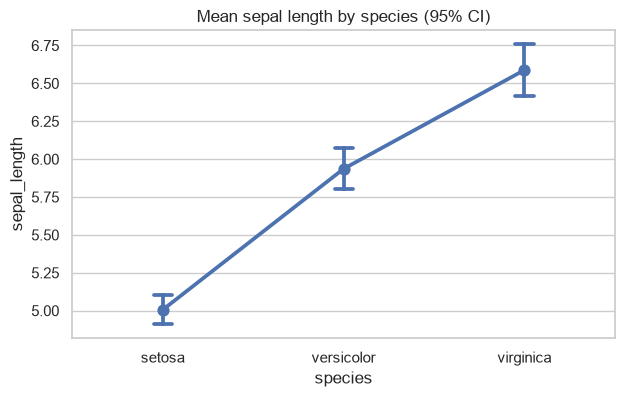

In [5]:
oneway_model = ols("sepal_length ~ C(species)", data=df).fit()
oneway_table = sm.stats.anova_lm(oneway_model, typ=2)
display(oneway_table)

anova_p = oneway_table.loc["C(species)", "PR(>F)"]
print("One-way ANOVA decision:", "Reject H0" if anova_p < ALPHA else "Fail to reject H0")

tukey = pairwise_tukeyhsd(endog=df["sepal_length"],
                          groups=df["species"], alpha=ALPHA)
print(tukey)

plt.figure(figsize=(7, 4))
sns.pointplot(data=df, x="species", y="sepal_length",
              errorbar=("ci", 95), capsize=0.1)
plt.title("Mean sepal length by species (95% CI)")
plt.show()

## 6. Two-way ANOVA with interaction

For the required demonstration, create a categorical petal-width factor (`narrow` / `wide`) by splitting at the overall median. Then examine sepal length using species, petal-width group, and their interaction.

### Hypotheses
- **Species main effect H₀:** Adjusted mean sepal length is equal across species.
- **Petal-width group main effect H₀:** Adjusted mean sepal length is equal for narrow and wide groups.
- **Interaction H₀:** The species effect does not depend on petal-width group.

A significant interaction means the association for one factor varies across levels of the other. Because petal-width group is derived from a measurement in this same dataset, interpret this model as a demonstration only, not a causal analysis.

Median petal width: 1.3


petal_width_group,narrow,wide
species,,
setosa,50,0
versicolor,28,22
virginica,0,50


C:\Users\SIDDHI\AppData\Local\Temp\ipykernel_22756\1909048160.py:9: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()
c:\Users\SIDDHI\Downloads\reproducible-research\.venv\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1
  res = self.wald_test(


,sum_sq,df,F,PR(>F)
C(species),1.288067e+00,2.0,2.663419e+00,1.048349e-01
C(petal_width_group),1.970535e-13,1.0,8.149204e-13,9.999993e-01
C(species):C(petal_width_group),6.622048e+01,2.0,1.369284e+02,3.246221e-34
Residual,3.530382e+01,146.0,NaN,NaN


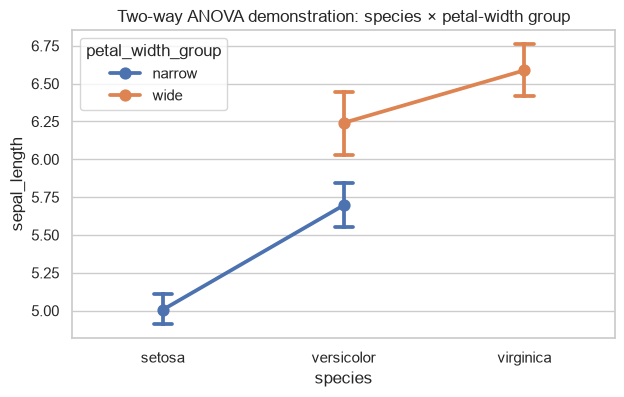

In [6]:
median_pw = df["petal_width"].median()
df["petal_width_group"] = np.where(df["petal_width"] <= median_pw, "narrow", "wide")

print("Median petal width:", median_pw)
display(pd.crosstab(df["species"], df["petal_width_group"]))

twoway_model = ols(
    "sepal_length ~ C(species) * C(petal_width_group)", data=df
).fit()
twoway_table = sm.stats.anova_lm(twoway_model, typ=2)
display(twoway_table)

plt.figure(figsize=(7, 4))
sns.pointplot(data=df, x="species", y="sepal_length",
              hue="petal_width_group", errorbar=("ci", 95), capsize=0.1)
plt.title("Two-way ANOVA demonstration: species × petal-width group")
plt.show()

## 7. Tukey HSD for species comparisons

In [7]:
# Tukey HSD for the three species, following the one-way ANOVA
tukey_species = pairwise_tukeyhsd(
    endog=df["sepal_length"], groups=df["species"], alpha=ALPHA
)
tukey_df = pd.DataFrame(
    data=tukey_species._results_table.data[1:],
    columns=tukey_species._results_table.data[0]
)
display(tukey_df)
print("The 'reject' column indicates whether a pairwise difference is statistically significant at alpha = 0.05.")

,group1,group2,meandiff,p-adj,lower,upper,reject
0,setosa,versicolor,0.930,0.0,0.6862,1.1738,True
1,setosa,virginica,1.582,0.0,1.3382,1.8258,True
2,versicolor,virginica,0.652,0.0,0.4082,0.8958,True


The 'reject' column indicates whether a pairwise difference is statistically significant at alpha = 0.05.


## 8. Automatically generated findings and conclusion

The cell below creates a concise report using the actual test outputs generated when the notebook runs. Do not report only statistical significance: include effect direction, confidence interval, sample size, and limitations.

In [ ]:
print("# Findings and conclusion\n")
print(f"- The dataset contains {len(df)} observations across {df['species'].nunique()} species, with no missing values in the bundled Iris data.")
print(f"- Welch's two-sample t-test comparing setosa and versicolor sepal length returned p={t_p:.6g}.")
print(f"- The estimated mean difference (setosa − versicolor) was {mean_diff:.3f} cm, with a 95% CI of [{ci_low:.3f}, {ci_high:.3f}] cm.")
print(f"- Mann–Whitney U returned p={mw_p:.6g}.")
print(f"- One-way ANOVA across species returned F={oneway_table.loc['C(species)', 'F']:.3f}, p={anova_p:.6g}.")
print("\nInterpretation at alpha = 0.05:")
print("- For each test, reject H0 when p < 0.05; otherwise, fail to reject H0.")
print("- A significant one-way ANOVA indicates at least one species mean differs; consult Tukey HSD for pairwise comparisons.")
print("- Normality-test results should be considered alongside Q-Q plots and the robustness of the chosen test.")
print("\nLimitations:")
print("- Iris is a teaching dataset, not a business dataset or a new scientific experiment.")
print("- Statistical significance does not by itself establish practical importance or causation.")
print("- The two-way ANOVA uses a median-derived petal-width group solely to demonstrate the requested method.")

## 9. Save tables for submission (optional)

This exports the main numerical results to CSV files in the notebook's current working directory. The notebook itself remains the primary deliverable.

In [8]:
normality.to_csv("normality_test_results.csv", index=False)
oneway_table.to_csv("one_way_anova_results.csv")
twoway_table.to_csv("two_way_anova_results.csv")
tukey_df.to_csv("tukey_hsd_results.csv", index=False)
print("Saved normality_test_results.csv, one_way_anova_results.csv, two_way_anova_results.csv, and tukey_hsd_results.csv")

Saved normality_test_results.csv, one_way_anova_results.csv, two_way_anova_results.csv, and tukey_hsd_results.csv
